In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os as os
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import pyogrio


In [54]:
zillowzipcode = pd.read_csv('zillowzipcode.csv', dtype={'RegionName': str})

In [55]:
# Make sure every ZIP is 5 digits (safety check; should already be true with dtype=str)
zillowzipcode['RegionName'] = zillowzipcode['RegionName'].str.zfill(5)

# Month columns are the ones whose names start with a year, e.g. '2026-09-30'
date_cols = [c for c in zillowzipcode.columns if c[:2] in ('19', '20')]
latest = date_cols[-1]

# Build a smaller table: location info + latest value + 12-month average
zillow = zillowzipcode[['RegionName', 'State', 'City', 'Metro', 'CountyName']].copy()
zillow['home_value'] = zillowzipcode[latest]
zillow['home_value_12mo'] = zillowzipcode[date_cols[-12:]].mean(axis=1)

# Rename RegionName to zip, and drop any ZIP without a current value
zillow = zillow.rename(columns={'RegionName': 'zip'}).dropna(subset=['home_value'])

print(zillow.shape)
zillow.head()

(26265, 7)


,zip,State,City,Metro,CountyName,home_value,home_value_12mo
0,77494,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Fort Bend County,478133.283602,484931.144288
1,08701,NJ,Lakewood,"New York-Newark-Jersey City, NY-NJ-PA",Ocean County,591112.377080,575704.983935
2,77449,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Harris County,264941.992324,268837.287339
3,78660,TX,Pflugerville,"Austin-Round Rock-Georgetown, TX",Travis County,364281.696137,371770.714759
4,77433,TX,Cypress,"Houston-The Woodlands-Sugar Land, TX",Harris County,422855.785146,425812.997557


In [56]:
zillow.isna().sum()

zip                   0
State                 0
City                  7
Metro              4709
CountyName            0
home_value            0
home_value_12mo       0
dtype: int64

In [57]:
# Check missing values: count and percent per column
missing = pd.DataFrame({
    'missing': zillow.isna().sum(),
    'percent': (zillow.isna().mean() * 100).round(1)
})
missing[missing['missing'] > 0]

,missing,percent
City,7,0.0
Metro,4709,17.9


In [58]:
zillow[zillow['Metro'].isna()].head()

,zip,State,City,Metro,CountyName,home_value,home_value_12mo
2477,77351,TX,Livingston,NaN,Polk County,183712.478187,189205.565749
3783,28734,NC,Franklin,NaN,Macon County,298222.164614,296734.822576
4128,30533,GA,Dahlonega,NaN,Lumpkin County,379853.397716,380365.174532
4329,22485,VA,King George,NaN,King George County,476334.748542,470272.094217
4666,28328,NC,Clinton,NaN,Sampson County,156376.334864,154433.594286


In [59]:
# Fill missing categories with a label instead of dropping rows.
# Metro is blank for ~4,709 rural ZIPs that aren't in any metro area. That's real
# information, not bad data, so we label them 'Non-metro' and keep them.
# City is blank for 7 ZIPs.
# fillna only fills empty cells; existing values are untouched.
# We do NOT fill numeric columns like home_value. Made-up prices would distort the model.
zillow['Metro'] = zillow['Metro'].fillna('Non-metro')
zillow['City'] = zillow['City'].fillna('Unknown')

# Verify: should print 0 for every column
zillow.isna().sum()

zip                0
State              0
City               0
Metro              0
CountyName         0
home_value         0
home_value_12mo    0
dtype: int64

## Zillow home value data (ZHVI)

**Source:** [Zillow Research Data](https://www.zillow.com/research/data/), Home Values, ZHVI, All Homes (SFR + Condo), mid-tier, smoothed & seasonally adjusted, ZIP code level.
**File:** `zillowzipcode.csv` (124 MB, not committed to git because GitHub's limit is 100 MB, so download it yourself and put it in the project folder)

**What it measures:** the typical value of a mid-priced home (33rd–67th percentile) in each ZIP code. This is **home value, not rent.**

**Layout:** one row per ZIP (26,265 ZIPs, 50 states + DC), with location columns (`RegionName` = ZIP, `State`, `City`, `Metro`, `CountyName`) followed by one column per month from 2000-01 to 2026-09.

**What we keep:** the location columns, plus
- `home_value`: the latest month's value (2026-09)
- `home_value_12mo`: average of the last 12 months, which is more stable than a single month

In [60]:
#IMPORTING SmartLocationDatabase.gdb
# EPA Smart Location Database: built-environment features per Census block group (~2018 data).
# read_geometry=False skips the map shapes, which we don't need, so loading is much faster.
sld_cols = ['GEOID10', 'STATEFP', 'TotPop', 'HH', 'Ac_Land', 'TotEmp',
            'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D4A', 'D5AR', 'NatWalkInd',
            'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker']
sld = pyogrio.read_dataframe('/Users/josiah/2302GroupProj/2302-group-proj/SmartLocationDatabase.gdb',
                             columns=sld_cols, read_geometry=False)

# EPA codes "no value" as -99999 (mostly transit columns), so turn it into real NaN
sld = sld.replace(-99999, np.nan)

# Drop territories (Zillow doesn't cover them) and block groups with nobody living there
sld = sld[~sld['STATEFP'].isin(['60', '66', '69', '72', '78'])]
sld = sld[sld['TotPop'] > 0]

# 1 if there's a transit stop within walking distance, 0 if not
sld['has_transit'] = sld['D4A'].notna().astype(int)

# First 11 digits of a block group ID = its tract ID
sld['tract'] = sld['GEOID10'].str[:11]

In [61]:
sld.head()

,GEOID10,STATEFP,Ac_Land,TotPop,HH,Pct_AO0,R_PCTLOWWAGE,TotEmp,D1A,D1C,D2B_E8MIXA,D3B,D4A,D5AR,NatWalkInd,VMT_per_worker,has_transit,tract
0,481130078254,48,73.595028,1202,423.0,0.163121,0.240291,66,6.250422,0.896800,0.662091,115.981747,362.10,433601.0,14.000000,27.496405,1,48113007825
1,481130078252,48,119.829909,710,409.0,0.000000,0.192405,25,3.430799,0.209707,0.554458,80.145600,718.84,386504.0,10.833333,26.465754,1,48113007825
2,481130078253,48,26.367053,737,329.0,0.057751,0.293737,0,13.843035,0.000000,-0.000000,24.272717,398.31,404573.0,8.333333,32.311348,1,48113007825
3,481130078241,48,119.060687,904,384.0,0.000000,0.139211,253,3.225246,2.124967,0.553831,141.604424,386.24,423099.0,15.666667,26.277851,1,48113007824
4,481130078242,48,169.927211,948,343.0,0.014577,0.157168,32,2.305992,0.215136,0.459064,65.307963,638.37,335700.0,10.166667,30.138550,1,48113007824


In [62]:
# Census crosswalk: which tracts overlap each ZIP, and how many people live in each overlapping piece.
# (Census calls them ZCTAs, which are their approximation of ZIP codes. 2010 boundaries, matching the SLD.)
# dtype=str keeps leading zeros on both IDs.
xw_url = 'https://www2.census.gov/geo/docs/maps-data/data/rel/zcta_tract_rel_10.txt'
xw = pd.read_csv(xw_url, usecols=['ZCTA5', 'GEOID', 'POPPT'], dtype={'ZCTA5': str, 'GEOID': str})
xw = xw.rename(columns={'ZCTA5': 'zip', 'GEOID': 'tract', 'POPPT': 'pop_in_zip'})

# Drop overlaps where nobody lives (e.g. a ZIP clipping an empty corner of a tract)
xw = xw[xw['pop_in_zip'] > 0]

In [64]:
# Features to average for each ZIP
rate_cols = ['D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd',
             'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']

# Population-weighted average of rate_cols within each group.
# Missing values are skipped (their weight isn't counted), so they don't drag averages toward 0.
def weighted_mean(df, group_col, weight_col):
    num = df[rate_cols].mul(df[weight_col], axis=0).groupby(df[group_col]).sum()
    den = df[rate_cols].notna().mul(df[weight_col], axis=0).groupby(df[group_col]).sum()
    return (num / den).reset_index()

# Step 1: block groups -> tracts, weighted by each block group's population
sld_by_tract = weighted_mean(sld, 'tract', 'TotPop')

# Step 2: tracts -> ZIPs, weighted by how many people live in each tract/ZIP overlap
xw_sld = xw.merge(sld_by_tract, on='tract', how='inner')
sld_zip = weighted_mean(xw_sld, 'zip', 'pop_in_zip')

print(sld_by_tract.shape)  # expect (72411, 11)
print(sld_zip.shape)       # expect (32843, 11)

(72411, 11)
(32843, 11)


**HOUSING = FINAL MERGE** 
Tract merge over zip


In [65]:
housing = zillow.merge(sld_zip, on='zip', how='inner', validate='one_to_one')

print(housing.shape)              # expect (26208, 17)
print(housing.isna().sum().sum()) # expect 0
housing.head()

(26208, 17)
0


,zip,State,City,Metro,CountyName,home_value,home_value_12mo,D1A,D1C,D2B_E8MIXA,D3B,D5AR,NatWalkInd,Pct_AO0,R_PCTLOWWAGE,VMT_per_worker,has_transit
0,77494,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Fort Bend County,478133.283602,484931.144288,1.967872,1.616427,0.648545,84.001783,146439.093830,8.922151,0.016480,0.155051,23.094927,0.000000
1,08701,NJ,Lakewood,"New York-Newark-Jersey City, NY-NJ-PA",Ocean County,591112.377080,575704.983935,3.224683,2.857382,0.675134,79.216684,51265.589422,12.496276,0.101892,0.247122,20.888325,0.750056
2,77449,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Harris County,264941.992324,268837.287339,2.691554,1.067385,0.707674,73.320469,163767.496211,7.960358,0.020130,0.211617,22.762545,0.000000
3,78660,TX,Pflugerville,"Austin-Round Rock-Georgetown, TX",Travis County,364281.696137,371770.714759,2.121436,1.298031,0.590008,63.756761,118761.623717,7.718608,0.021557,0.185028,26.364063,0.087743
4,77433,TX,Cypress,"Houston-The Woodlands-Sugar Land, TX",Harris County,422855.785146,425812.997557,2.154172,0.567788,0.701200,70.489159,158239.221527,8.152881,0.008932,0.179233,25.060340,0.000000


In [66]:
# Which Zillow ZIPs didn't match?
unmatched = zillow[~zillow['zip'].isin(sld_zip['zip'])]
print(len(unmatched), 'unmatched')
unmatched.head(10)

57 unmatched


,zip,State,City,Metro,CountyName,home_value,home_value_12mo
542,75033,TX,Frisco,"Dallas-Fort Worth-Arlington, TX",Denton County,6.457587e+05,6.578532e+05
588,75072,TX,McKinney,"Dallas-Fort Worth-Arlington, TX",Collin County,5.079001e+05,5.162288e+05
1333,11249,NY,New York,"New York-Newark-Jersey City, NY-NJ-PA",Kings County,1.535012e+06,1.518567e+06
1414,29486,SC,Summerville,"Charleston-North Charleston, SC",Berkeley County,4.095165e+05,4.092973e+05
1657,84009,UT,South Jordan,"Salt Lake City, UT",Salt Lake County,6.109764e+05,6.124926e+05
2210,84129,UT,Taylorsville,"Salt Lake City, UT",Salt Lake County,4.884515e+05,4.896140e+05
2885,75036,TX,Frisco,"Dallas-Fort Worth-Arlington, TX",Denton County,5.550980e+05,5.655531e+05
3018,78599,TX,Weslaco,"McAllen-Edinburg-Mission, TX",Hidalgo County,1.858250e+05,1.869699e+05
3379,97703,OR,Bend,"Bend, OR",Deschutes County,9.941397e+05,9.918143e+05
3682,99623,AK,Wasilla,"Anchorage, AK",Matanuska Susitna Borough,3.756298e+05,3.692876e+05


In [67]:
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

STATE_FIPS, STATE = '37', 'NC'
ZOOM_COUNTY = '119'            # Mecklenburg County (Charlotte)
CRS = 'EPSG:32119'             # NC State Plane projection (meters), so the state isn't stretched

# Tract shapes: load NC block group shapes from the SLD and merge them into tracts
bg = pyogrio.read_dataframe('SmartLocationDatabase.gdb',
                            columns=['GEOID10', 'STATEFP', 'COUNTYFP'],
                            where=f"STATEFP = '{STATE_FIPS}'")
bg['tract'] = bg['GEOID10'].str[:11]
tracts = bg.dissolve(by='tract', aggfunc={'COUNTYFP': 'first'}).reset_index().to_crs(CRS)

# ZIP shapes: Census 2010 ZIP boundaries for NC, joined to our home values
zcta_url = 'https://www2.census.gov/geo/tiger/TIGER2010/ZCTA5/2010/tl_2010_37_zcta510.zip'
zips = gpd.read_file(zcta_url)[['ZCTA5CE10', 'geometry']].rename(columns={'ZCTA5CE10': 'zip'}).to_crs(CRS)
zips = zips.merge(housing[housing['State'] == STATE][['zip', 'home_value']], on='zip', how='left')

print(len(tracts), 'tracts |', len(zips), 'ZIPs |', zips['home_value'].notna().sum(), 'with home values')
# expect: 2195 tracts | 808 ZIPs | 717 with home values

2195 tracts | 808 ZIPs | 717 with home values


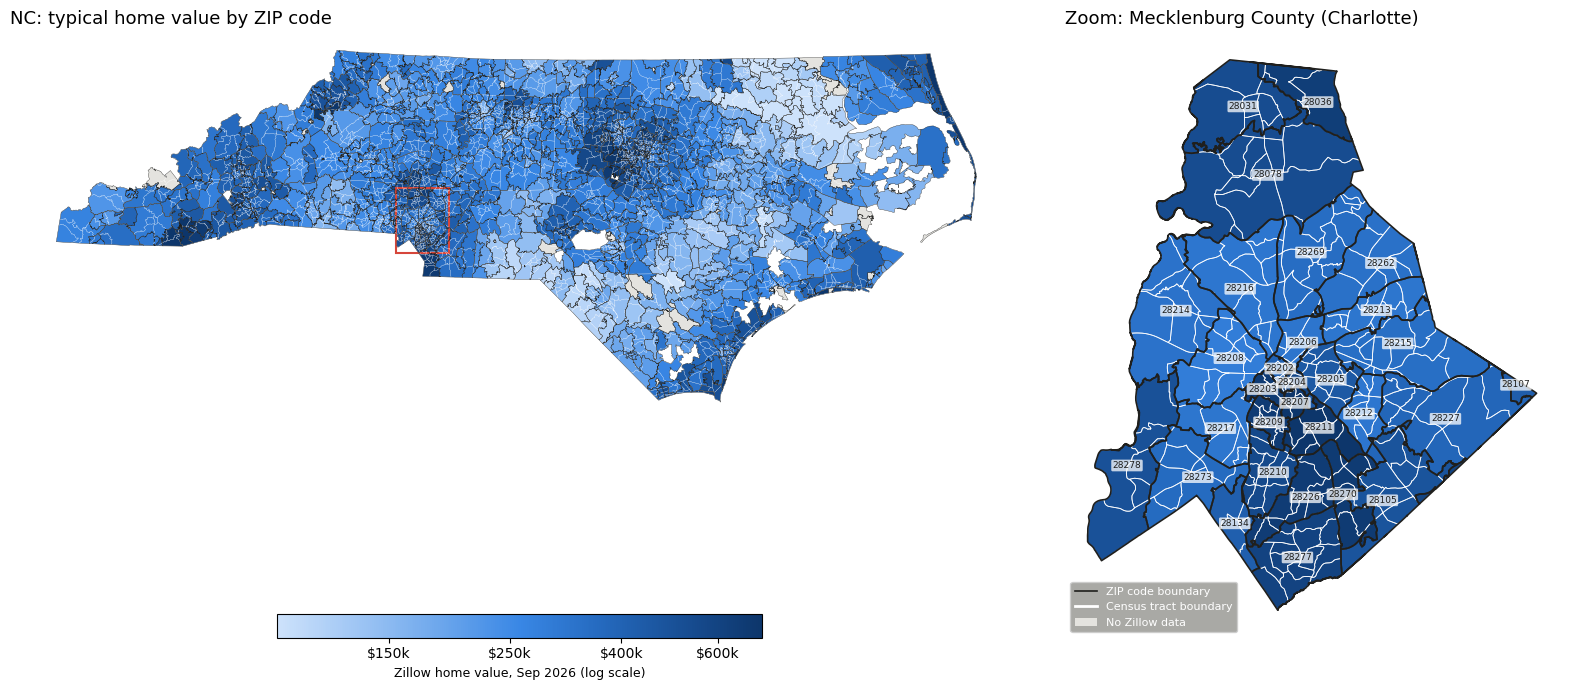

In [68]:
# Light-to-dark blue for home value; log scale so a few $1M+ ZIPs don't wash out everything else
ramp = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
cmap = LinearSegmentedColormap.from_list('blue_seq', ramp)
norm = LogNorm(vmin=zips['home_value'].quantile(0.02), vmax=zips['home_value'].quantile(0.98))

def draw(ax, z, t, zip_lw, tract_lw, label=False):
    z[z['home_value'].isna()].plot(ax=ax, color='#e4e3df', edgecolor='none')               # no Zillow data
    z[z['home_value'].notna()].plot(ax=ax, column='home_value', cmap=cmap, norm=norm, edgecolor='none')
    t.boundary.plot(ax=ax, color='white', linewidth=tract_lw, alpha=0.9)                    # tract lines
    z.boundary.plot(ax=ax, color='#1f1f1d', linewidth=zip_lw)                               # ZIP lines on top
    if label:
        for _, r in z[z.area > 4e6].iterrows():   # skip slivers too small to label
            p = r.geometry.representative_point()
            ax.annotate(r['zip'], (p.x, p.y), ha='center', va='center', fontsize=6.5, color='#1f1f1d',
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))
    ax.set_axis_off()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.9, 1]})

# Left: whole state
draw(ax1, zips, tracts, zip_lw=0.25, tract_lw=0.15)
ax1.set_title(f'{STATE}: typical home value by ZIP code', loc='left', fontsize=13)

# Right: zoom into one county, with ZIPs cut to the county edge
zoom_t = tracts[tracts['COUNTYFP'] == ZOOM_COUNTY]
zoom_z = gpd.clip(zips, zoom_t.union_all())
draw(ax2, zoom_z, zoom_t, zip_lw=1.2, tract_lw=0.6, label=True)
ax2.set_title('Zoom: Mecklenburg County (Charlotte)', loc='left', fontsize=13)

# Red box on the state map showing where the zoom is
xmin, ymin, xmax, ymax = zoom_t.total_bounds
ax1.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, ec='#d6463b', lw=1.5))

# Color bar and legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cb = fig.colorbar(sm, ax=ax1, orientation='horizontal', fraction=0.04, pad=0.02, shrink=0.6)
ticks = [150_000, 250_000, 400_000, 600_000]
cb.set_ticks(ticks); cb.set_ticklabels([f'${t//1000}k' for t in ticks]); cb.minorticks_off()
cb.set_label('Zillow home value, Sep 2026 (log scale)', fontsize=9)
ax2.legend(handles=[Line2D([], [], color='#1f1f1d', lw=1.2, label='ZIP code boundary'),
                    Line2D([], [], color='white', lw=2, label='Census tract boundary'),
                    Patch(fc='#e4e3df', label='No Zillow data')],
           loc='lower left', fontsize=8, frameon=True, facecolor='#9a9a96', framealpha=0.85, labelcolor='white')

ax1.set_anchor('N'); ax2.set_anchor('N')
plt.tight_layout()
plt.show()

# 📋 Info for Coders

> ✅ **All variables below are cleaned and finalized.** Run the notebook top to bottom before using them.

| Variable | What it is | One row per | Rows |
|---|---|---|---|
| `zillow` | Zillow home values, from `zillowzipcode.csv` | ZIP code | 26,265 |
| `sld` | EPA Smart Location Database (walkability, density, transit, job access) | Census block group | 216,682 |
| `housing` | **Final merged table:** `zillow` + SLD features averaged up to each ZIP | ZIP code | 26,208 |

### Notes
- **`zillow` covers all 50 states + DC**, not just NC.
- **`housing` is the table to use for modeling.** SLD data is by Census tract, so it was mapped to ZIP codes using the Census ZIP-to-tract crosswalk (population-weighted).
- **57 Zillow ZIPs didn't match** (mostly ZIPs created after 2010) and are not in `housing`.
- **ZIP codes are strings**, not numbers (keeps leading zeros like `08701`). Always merge on `zip` as text.